# 2.0 — Análisis de riesgo operativo por estación (P2)
**Proyecto MiBici 2024 · Equipo 15 · análisis exploratorio previo al baseline**

**Pregunta P2:** ¿Una estación estará en riesgo de quedarse sin bicicletas o sin anclajes disponibles durante la siguiente hora?

**Propósito:** verificar la nomenclatura de estaciones, construir un **indicador proxy** a partir de llegadas, salidas y capacidad, analizar su distribución y evaluar umbrales de clasificación. **No se entrenan modelos en este notebook.**

> **Limitación:** no hay inventario histórico ni registros de rebalanceo. Un flujo neto horario grande respecto de la capacidad representa presión operativa, **no evidencia de agotamiento real**. El catálogo disponible es de septiembre de 2026 y sus capacidades podrían diferir de las de 2024. No se exportan datos de usuarios ni se modifica ningún CSV original.


## 0. Configuración, fuentes y entorno

Ejecutar con el kernel `mlops` desde la carpeta `notebooks/` o desde la raíz del proyecto. No es necesario volver a ejecutar el notebook EDA de P1.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
if (cwd / "data" / "raw").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "raw").is_dir():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(f"No se localizó data/raw desde {cwd}")

DATA_RAW = PROJECT_ROOT / "data" / "raw"
FILES = sorted(DATA_RAW.glob("datos_abiertos_2024_*.csv"))
STATIONS_FILE = DATA_RAW / "nomenclatura_2026_09.csv"
CHUNKSIZE = 100_000

assert len(FILES) == 12, f"Se esperaban 12 meses; se encontraron {len(FILES)}"
assert STATIONS_FILE.is_file(), "No se encontró la nomenclatura de 2026"
print("Proyecto:", PROJECT_ROOT)
print("Viajes:", len(FILES), "CSV de 2024")
print("Nomenclatura:", STATIONS_FILE.name)
print("Pandas:", pd.__version__)


Proyecto: /Users/josemtzromero01/Documents/Maestria-MNA/MLOps/week5/TC5061-Proyecto-Equipo15
Viajes: 12 CSV de 2024
Nomenclatura: nomenclatura_2026_09.csv
Pandas: 3.0.6


## 1. Inspección de la nomenclatura

Identificamos **sin asumir** los nombres del ID y la capacidad, su tipo, los valores faltantes y los IDs duplicados. La selección automatizada se hace solo si el encabezado es inequívoco.

In [2]:
catalogo = pd.read_csv(STATIONS_FILE, dtype=str, encoding="utf-8-sig")
catalogo.columns = catalogo.columns.astype(str).str.strip()
print("Dimensiones de nomenclatura:", catalogo.shape)
print("Columnas originales:", catalogo.columns.tolist())
display(catalogo.head(5))
display(pd.DataFrame({"columna": catalogo.columns,
                      "faltantes": catalogo.isna().sum().to_numpy(),
                      "porcentaje": (100 * catalogo.isna().mean()).round(2).to_numpy()}))


Dimensiones de nomenclatura: (484, 5)
Columnas originales: ['id', 'name', 'latitude', 'longitude', 'dpcapacity']


,id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.34882,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.66769,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691846603895982,-103.3625486588955,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.6811575,-103.339363,11


,columna,faltantes,porcentaje
0,id,0,0.0
1,name,0,0.0
2,latitude,0,0.0
3,longitude,0,0.0
4,dpcapacity,0,0.0


In [3]:
# Si los nombres no coinciden, definir manualmente ID_COL y CAPACITY_COL
# mirando la salida anterior; no cambiar los CSV originales.
def busca_columna(columnas, alternativas):
    normal = {c: re.sub(r"[^a-z0-9]+", "", c.lower()) for c in columnas}
    coincidentes = [c for c, n in normal.items() if n in alternativas]
    return coincidentes[0] if len(coincidentes) == 1 else None

ID_COL = busca_columna(catalogo.columns, {"id", "estacionid", "idestacion", "stationid"})
ID_COL = "id"
CAPACITY_COL = "dpcapacity"

print("Columna ID:", ID_COL)
print("Columna capacidad:", CAPACITY_COL)

print("Columna ID propuesta:", ID_COL)
print("Columna capacidad propuesta:", CAPACITY_COL)
if ID_COL is None or CAPACITY_COL is None:
    raise ValueError(
        "Revisa las columnas mostradas arriba y asigna manualmente ID_COL y "
        "CAPACITY_COL en esta celda según los encabezados reales."
    )

capacidades = catalogo[[ID_COL, CAPACITY_COL]].copy()
capacidades.columns = ["estacion", "capacidad_original"]
capacidades["estacion"] = capacidades["estacion"].astype("string").str.strip()
capacidades["capacidad"] = pd.to_numeric(
    capacidades["capacidad_original"].str.strip().str.replace(",", "", regex=False),
    errors="coerce"
)
print("Filas:", len(capacidades))
print("IDs vacíos:", int(capacidades["estacion"].isna().sum() +
                        capacidades["estacion"].eq("").fillna(False).sum()))
print("IDs duplicados:", int(capacidades["estacion"].duplicated().sum()))
print("Capacidades ausentes/no numéricas:", int(capacidades["capacidad"].isna().sum()))
print("Capacidades <= 0:", int(capacidades["capacidad"].le(0).sum()))
print("Capacidades no enteras:", int(
    (capacidades["capacidad"].notna() &
     capacidades["capacidad"].ne(np.floor(capacidades["capacidad"]))).sum()))
display(capacidades["capacidad"].describe().to_frame("capacidad"))
display(capacidades.loc[capacidades["estacion"].duplicated(keep=False)]
        .sort_values("estacion").head(20))


Columna ID: id
Columna capacidad: dpcapacity
Columna ID propuesta: id
Columna capacidad propuesta: dpcapacity
Filas: 484
IDs vacíos: 0
IDs duplicados: 0
Capacidades ausentes/no numéricas: 0
Capacidades <= 0: 4
Capacidades no enteras: 0


,capacidad
count,484.000000
mean,16.882231
std,4.126942
min,0.000000
25%,15.000000
50%,15.000000
75%,19.000000
max,39.000000


,estacion,capacidad_original,capacidad


## 2. Validación de capacidad por estación

No sumamos arbitrariamente filas duplicadas de catálogo. Si una estación presenta capacidades contradictorias, la excluimos del cálculo hasta investigar el caso. Solo utilizamos capacidades positivas y enteras, según el catálogo de 2026.


In [4]:
valid = capacidades.loc[
    capacidades["estacion"].notna()
    & capacidades["estacion"].ne("")
    & capacidades["capacidad"].gt(0)
    & capacidades["capacidad"].eq(np.floor(capacidades["capacidad"]))
].copy()
variantes = valid.groupby("estacion")["capacidad"].nunique()
conflictivas = set(variantes[variantes > 1].index)
mapa_capacidades = (valid.loc[~valid["estacion"].isin(conflictivas)]
                   .drop_duplicates("estacion").set_index("estacion")["capacidad"])
print("Estaciones con capacidad válida única:", len(mapa_capacidades))
print("IDs con capacidades contradictorias:", len(conflictivas))
print("Capacidad mínima y máxima:",
      mapa_capacidades.min(), mapa_capacidades.max())
if conflictivas:
    print("IDs conflictivos (hasta 20):", sorted(conflictivas)[:20])


Estaciones con capacidad válida única: 480
IDs con capacidades contradictorias: 0
Capacidad mínima y máxima: 11 39


## 3. Agregación horaria de entradas y salidas

Se procesan **únicamente** identificadores de estación y fechas (sin identificadores de viaje o usuario). Para salidas usamos la hora de inicio y para llegadas la hora de fin. Los meses 09 y 10 tienen precisión de minutos; otros meses, de segundos. El procesamiento se realiza en bloques de 100,000 filas.

**Importante:** si una fecha de finalización cae en el mes siguiente o fuera de 2024, la agrupación usa su fecha real y después el panel se restringe al año 2024. No se atribuyen llegadas a una hora incorrecta.


In [5]:
def columnas_de_viajes(chunk):
    if len(chunk.columns) != 8:
        raise ValueError(f"Se esperaban 8 columnas; se encontraron {len(chunk.columns)}")
    chunk.columns = [
        "viaje_id", "usuario_id", "genero", "anio_nacimiento",
        "inicio", "fin", "origen", "destino"
    ]
    return chunk

def convertir_fechas(serie, mes):
    formato = "%d/%m/%Y %H:%M" if mes in (9, 10) else "%Y-%m-%d %H:%M:%S"
    return pd.to_datetime(serie, format=formato, errors="coerce")

# Acumulamos pequeños agrupados por bloque, no viajes individuales.
resumenes = []
errores_fechas = []
for path in FILES:
    mes = int(path.stem[-2:])
    enc = "utf-8" if mes == 7 else "latin1"
    invalidos_inicio = invalidos_fin = n_mes = 0
    for chunk in pd.read_csv(path, dtype=str, chunksize=CHUNKSIZE, encoding=enc):
        chunk = columnas_de_viajes(chunk)
        n_mes += len(chunk)
        for tipo, campo_fecha, campo_estacion in [
            ("salidas", "inicio", "origen"),
            ("llegadas", "fin", "destino")
        ]:
            fechas = convertir_fechas(chunk[campo_fecha], mes)
            estaciones = chunk[campo_estacion].astype("string").str.strip()
            if tipo == "salidas":
                invalidos_inicio += int(fechas.isna().sum())
            else:
                invalidos_fin += int(fechas.isna().sum())
            tmp = pd.DataFrame({
                "hora": fechas.dt.floor("h"), "estacion": estaciones
            }).dropna()
            tmp = tmp.loc[tmp["estacion"].ne("")]
            grouped = tmp.groupby(["estacion", "hora"], observed=True).size()
            if len(grouped):
                resumenes.append(grouped.rename(tipo).reset_index())
    errores_fechas.append({
        "mes": mes, "viajes": n_mes,
        "fecha_inicio_invalida": invalidos_inicio,
        "fecha_fin_invalida": invalidos_fin
    })
    print(f"{path.name}: {n_mes:,} viajes")

assert resumenes, "No se pudieron calcular flujos"
display(pd.DataFrame(errores_fechas))


datos_abiertos_2024_01.csv: 391,591 viajes
datos_abiertos_2024_02.csv: 383,732 viajes
datos_abiertos_2024_03.csv: 390,513 viajes
datos_abiertos_2024_04.csv: 405,308 viajes
datos_abiertos_2024_05.csv: 410,806 viajes
datos_abiertos_2024_06.csv: 365,000 viajes
datos_abiertos_2024_07.csv: 364,177 viajes
datos_abiertos_2024_08.csv: 394,894 viajes
datos_abiertos_2024_09.csv: 390,072 viajes
datos_abiertos_2024_10.csv: 418,690 viajes
datos_abiertos_2024_11.csv: 391,089 viajes
datos_abiertos_2024_12.csv: 340,049 viajes


,mes,viajes,fecha_inicio_invalida,fecha_fin_invalida
0,1,391591,0,0
1,2,383732,0,0
2,3,390513,0,0
3,4,405308,0,0
4,5,410806,0,0
5,6,365000,0,0
6,7,364177,0,0
7,8,394894,0,0
8,9,390072,0,0
9,10,418690,0,0


In [6]:
flujos_parciales = pd.concat(resumenes, ignore_index=True)
flujos_agrupados = (flujos_parciales
    .groupby(["estacion", "hora"], as_index=False)[["salidas", "llegadas"]]
    .sum()
    .fillna(0))
flujos_agrupados[["salidas", "llegadas"]] = (
    flujos_agrupados[["salidas", "llegadas"]].astype("int64")
)
flujos_agrupados = flujos_agrupados.loc[
    flujos_agrupados["hora"].ge(pd.Timestamp("2024-01-01"))
    & flujos_agrupados["hora"].lt(pd.Timestamp("2025-01-01"))
].copy()
print("Estaciones distintas en flujos:", flujos_agrupados["estacion"].nunique())
print("Combinaciones estación-hora con algún flujo:", len(flujos_agrupados))
print("Salidas 2024:", f'{flujos_agrupados["salidas"].sum():,}')
print("Llegadas fechadas en 2024:", f'{flujos_agrupados["llegadas"].sum():,}')


Estaciones distintas en flujos: 370
Combinaciones estación-hora con algún flujo: 1874372
Salidas 2024: 4,645,921
Llegadas fechadas en 2024: 4,645,917


## 4. Cobertura de capacidad y balance

Balance \(B_{s,t}=llegadas-salidas\): valor negativo indica presión hacia escasez de bicicletas y positivo presión hacia escasez de anclajes.

Presión proxy \(R_{s,t}=|B_{s,t}|/capacidad_s\).

**Este indicador no equivale a ocupación ni disponibilidad real.** El balance neto horario puede ocultar desequilibrios transitorios dentro de la hora.


In [7]:
ids_flujos = set(flujos_agrupados["estacion"].unique())
ids_sin_capacidad = sorted(ids_flujos - set(mapa_capacidades.index))
print("IDs observados en 2024:", len(ids_flujos))
print("Sin capacidad válida única:", len(ids_sin_capacidad))
print("IDs sin capacidad (hasta 20):", ids_sin_capacidad[:20])
flujos_con_capacidad = flujos_agrupados.loc[
    flujos_agrupados["estacion"].isin(mapa_capacidades.index)
].copy()
flujos_con_capacidad["capacidad"] = flujos_con_capacidad["estacion"].map(mapa_capacidades)
flujos_con_capacidad["balance"] = (
    flujos_con_capacidad["llegadas"] - flujos_con_capacidad["salidas"]
)
flujos_con_capacidad["presion"] = (
    flujos_con_capacidad["balance"].abs() / flujos_con_capacidad["capacidad"]
)
display(flujos_con_capacidad[["salidas","llegadas","balance","presion"]].describe().T)


IDs observados en 2024: 370
Sin capacidad válida única: 0
IDs sin capacidad (hasta 20): []


,count,mean,std,min,25%,50%,75%,max
salidas,1874372.0,2.478655,2.980191,0.0,1.000000,2.000000,3.000000,86.000000
llegadas,1874372.0,2.478653,3.201039,0.0,1.000000,2.000000,3.000000,125.000000
balance,1874372.0,-0.000002,2.619810,-70.0,-1.000000,0.000000,1.000000,105.000000
presion,1874372.0,0.102143,0.102385,0.0,0.052632,0.066667,0.133333,2.692308


## 5. Sensibilidad a distintos umbrales

Comparamos los umbrales propuestos **0.10, 0.25, 0.50 y 0.75** antes de seleccionar el del baseline P2. La proporción de alertas se calcula tanto:

- entre horas con algún flujo observado;
- como sobre **todas las horas del año × estaciones válidas**, asignando balance cero a horas sin eventos.

La segunda tasa es una *aproximación* y supone que todas las estaciones estuvieron operativas todo el año. No es una tasa de riesgo real ni una verdad de terreno.


In [8]:
UMBRales = [0.10, 0.25, 0.50, 0.75]
total_horas_2024 = 366 * 24  # año bisiesto
n_estaciones = flujos_con_capacidad["estacion"].nunique()
panel_teorico = n_estaciones * total_horas_2024
resumen_umbral = []
for umbral in UMBRales:
    altas = flujos_con_capacidad["presion"].ge(umbral)
    altas_num = int(altas.sum())
    hacia_bicis = int((altas & flujos_con_capacidad["balance"].lt(0)).sum())
    hacia_anclajes = int((altas & flujos_con_capacidad["balance"].gt(0)).sum())
    resumen_umbral.append({
        "umbral": umbral,
        "alertas": altas_num,
        "hacia_escasez_bicis": hacia_bicis,
        "hacia_escasez_anclajes": hacia_anclajes,
        "pct_horas_con_flujo": round(100 * altas_num / len(flujos_con_capacidad), 4),
        "pct_panel_teorico": round(100 * altas_num / panel_teorico, 4),
    })
tabla_umbrales = pd.DataFrame(resumen_umbral)
display(tabla_umbrales)
print("Panel teórico de estación-hora:", f"{panel_teorico:,}")
print("Importante: el catálogo de capacidades corresponde a 2026, no 2024.")


,umbral,alertas,hacia_escasez_bicis,hacia_escasez_anclajes,pct_horas_con_flujo,pct_panel_teorico
0,0.10,678362,345270,333092,36.1914,20.8722
1,0.25,164250,85576,78674,8.7629,5.0537
2,0.50,14779,7423,7356,0.7885,0.4547
3,0.75,2526,728,1798,0.1348,0.0777


Panel teórico de estación-hora: 3,250,080
Importante: el catálogo de capacidades corresponde a 2026, no 2024.


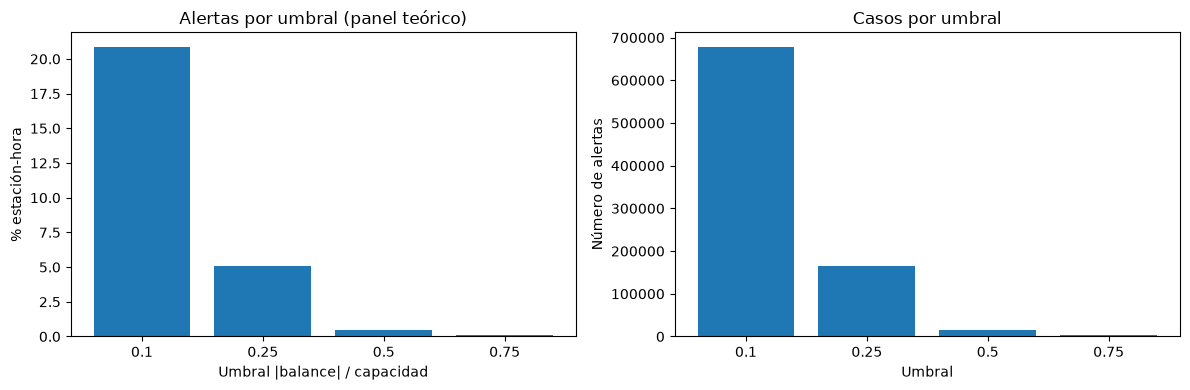

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(tabla_umbrales["umbral"].astype(str), tabla_umbrales["pct_panel_teorico"])
axes[0].set(title="Alertas por umbral (panel teórico)",
            xlabel="Umbral |balance| / capacidad", ylabel="% estación-hora")
axes[1].bar(tabla_umbrales["umbral"].astype(str), tabla_umbrales["alertas"])
axes[1].set(title="Casos por umbral", xlabel="Umbral", ylabel="Número de alertas")
plt.tight_layout()
plt.show()


## 6. Estabilidad mensual y partición temporal

La decisión del umbral no debe tomarse utilizando noviembre y diciembre (prueba). Separamos los periodos como en P1: entrenamiento enero–agosto, validación septiembre–octubre y prueba noviembre–diciembre.

Para una clasificación predictiva real, las **etiquetas** se calculan con flujos de la hora futura, pero las **variables de entrada** solo podrán usar información conocida antes de ella.


In [10]:
base = flujos_con_capacidad.copy()
base["periodo"] = np.select(
    [
        base["hora"] < pd.Timestamp("2024-09-01"),
        base["hora"] < pd.Timestamp("2024-11-01")
    ],
    ["train", "val"], default="test"
)
base["mes"] = base["hora"].dt.month
for u in [0.25, 0.50]:
    base[f"proxy_{str(u).replace('.', '_')}"] = base["presion"].ge(u).astype("int8")
tabla_mensual = (base.groupby(["periodo", "mes"], as_index=False)
    .agg(horas_con_flujo=("presion", "size"),
         alertas_025=("proxy_0_25", "sum"),
         alertas_050=("proxy_0_5", "sum")))
tabla_mensual["pct_025_horas_con_flujo"] = (
    100 * tabla_mensual["alertas_025"] / tabla_mensual["horas_con_flujo"]
).round(3)
tabla_mensual["pct_050_horas_con_flujo"] = (
    100 * tabla_mensual["alertas_050"] / tabla_mensual["horas_con_flujo"]
).round(3)
display(tabla_mensual.sort_values("mes"))


,periodo,mes,horas_con_flujo,alertas_025,alertas_050,pct_025_horas_con_flujo,pct_050_horas_con_flujo
2,train,1,155103,13770,1271,8.878,0.819
3,train,2,147393,13762,1329,9.337,0.902
4,train,3,156786,13672,1266,8.720,0.807
5,train,4,156269,14967,1497,9.578,0.958
6,train,5,162431,14979,1491,9.222,0.918
7,train,6,153843,13052,1105,8.484,0.718
8,train,7,156275,12718,1059,8.138,0.678
9,train,8,159878,13872,1175,8.677,0.735
10,val,9,155400,13658,1178,8.789,0.758
11,val,10,161756,14862,1312,9.188,0.811


## 7. Conclusiones y decisiones preliminares para el baseline P2

### 7.1. Calidad de la nomenclatura y cobertura de estaciones

Se examinaron **484 registros** del catálogo de estaciones de septiembre de 2026. Las columnas requeridas son `id` y `dpcapacity`. No se detectaron identificadores vacíos o duplicados ni capacidades faltantes, no numéricas o fraccionarias. Se encontraron **4 estaciones con capacidad igual a cero**, que se excluyeron del denominador para evitar divisiones inválidas. Las **480 estaciones restantes** presentan capacidad válida (entre **11 y 39** anclajes).

Los viajes de 2024 corresponden a **370 identificadores de estaciones**, todos presentes entre las estaciones con capacidad válida. En consecuencia, **ninguna estación observada en 2024 quedó fuera del cálculo por falta de capacidad**. No se imputaron valores.

**Limitación histórica:** la capacidad procede de un catálogo de **2026**, no de una fotografía de la infraestructura de 2024. Por ello, el análisis supone capacidades de referencia y no demuestra que las estaciones tuvieran esas mismas capacidades durante los viajes estudiados.

### 7.2. Integración temporal de viajes y balance de flujos

Los 12 CSV aportaron **4,645,921 salidas** iniciadas en 2024 y **4,645,917 llegadas** fechadas en 2024, con **cero fechas inválidas** en ambas columnas. La diferencia de **4 llegadas** necesita una comprobación específica de registros en el límite de año; **no se ha confirmado todavía** que sus fechas de finalización correspondan a 2025.

Se construyeron **1,874,372 combinaciones estación-hora con alguna salida o llegada**. El balance se definió como:

\[
B_{s,t}=\text{llegadas}_{s,t}-\text{salidas}_{s,t}
\]

Un balance negativo representa más salidas que llegadas (presión potencial hacia falta de bicicletas); uno positivo representa más llegadas que salidas (presión potencial hacia falta de anclajes).

Se observó un rango de balances de **−70 a 105** viajes netos por estación-hora; el indicador de presión alcanzó un máximo de aproximadamente **2.69**. Que la presión exceda 1 demuestra que **no puede interpretarse como porcentaje de ocupación**. Podrían intervenir movimientos repetidos dentro de la hora, rebalanceos no observados o diferencias históricas de capacidad.

### 7.3. Indicador proxy y sensibilidad a umbrales

Se calculó un indicador exploratorio de presión relativa:

\[
R_{s,t}=\frac{|B_{s,t}|}{C_s}
\]

donde \(C_s\) es la capacidad positiva de referencia. Para clasificar una observación como **alerta proxy**, se comprueba \(R_{s,t}\geq\tau\) para un umbral \(\tau\).

| Umbral \(\tau\) | Alertas | Presión hacia bicicletas | Presión hacia anclajes | % horas con flujo | % panel anual teórico |
|---|---:|---:|---:|---:|---:|
| 0.10 | 678,362 | 345,270 | 333,092 | 36.1914 % | 20.8722 % |
| 0.25 | 164,250 | 85,576 | 78,674 | 8.7629 % | 5.0537 % |
| 0.50 | 14,779 | 7,423 | 7,356 | 0.7885 % | 0.4547 % |
| 0.75 | 2,526 | 728 | 1,798 | 0.1348 % | 0.0777 % |

**Los porcentajes tienen denominadores distintos.** Las horas con flujo solo incluyen combinaciones donde hubo al menos un movimiento; el panel anual teórico considera **370 estaciones × 8,784 horas de 2024 = 3,250,080 observaciones**, suponiendo presencia y operación de todas las estaciones durante todo el año. Esta última es una suposición analítica, no disponibilidad operativa confirmada.

### 7.4. Selección preliminar del umbral

Se propone **\(\tau=0.25\) como valor inicial para el baseline P2**, porque evita la frecuencia extremadamente baja del umbral 0.50 y produce una prevalencia más utilizable para explorar clasificación. No se presenta como un umbral operativo validado por MiBici.

Las tasas mensuales de alertas con umbral 0.25, **entre horas con flujo**, fueron de aproximadamente **8.14 % a 9.58 %** durante entrenamiento (enero–agosto) y de **8.79 % a 9.19 %** durante validación (septiembre–octubre). Esto aporta evidencia inicial de estabilidad relativa. Los meses de noviembre–diciembre corresponden a **prueba** y no deben emplearse para escoger o ajustar el umbral.

El umbral se contrastará con al menos 0.50 usando solamente entrenamiento y validación; deberán compararse prevalencia, precision, recall, F1 y consecuencias de alertas falsas. Su selección definitiva queda **pendiente de los experimentos**.

### 7.5. Próximo experimento de clasificación

La unidad de modelado será **estación × hora**, con una etiqueta binaria derivada de la **presión proxy en la hora futura**. Los predictores solo podrán incluir información disponible antes de esa hora; **no se utilizará su balance observado para predecir su propia etiqueta**.

Se utilizará la misma división cronológica acordada para P1:

- **Entrenamiento:** enero–agosto de 2024.
- **Validación:** septiembre–octubre de 2024.
- **Prueba:** noviembre–diciembre de 2024.

El pipeline de entrenamiento deberá construir explícitamente el panel estación-hora, incluidas las horas sin movimientos, y evaluar dos referencias: **`DummyClassifier` (clase mayoritaria)** y **probabilidad histórica por estación/día/hora** calculada sin datos futuros. Se registrarán en MLflow **precision, recall, F1, matriz de confusión y parámetros de selección del umbral**; PR-AUC podrá complementar el análisis del desbalance cuando corresponda.

### 7.6. Limitaciones y pendientes

1. **No contamos con inventario histórico, ocupación ni movimientos de rebalanceo.** Las alertas representan **presión de flujos**, no evidencia de bicicletas o anclajes realmente agotados.
2. Las capacidades provienen de **septiembre de 2026** y pueden no representar 2024.
3. El balance neto agregado por hora puede ocultar desequilibrios transitorios dentro de la misma hora.
4. Completar con cero las horas sin viajes es una decisión de modelado; no demuestra que una estación estuviera operativa durante cada hora del año.
5. Investigar los **4 registros de diferencia** entre salidas de 2024 y llegadas fechadas en ese año.
6. Implementar funciones reutilizables en `mibici/dataset.py` y `mibici/features.py`, y registrar los baselines desde `mibici/modeling/p2_baseline.py`, **no únicamente desde este notebook**.
7. Mantener los archivos originales de MiBici y cualquier resultado local con datos a nivel de viaje fuera del repositorio Git.

**Conclusión:** los datos permiten construir y evaluar una **clasificación de presión operativa proxy** para P2. El umbral 0.25 es una **decisión experimental provisional**, no una medida validada del riesgo real de desabasto.
